In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import math

from rvsablation.utils import PrecompLatentTransitionDataset
from rvsablation.core import _TransformerStack
from rvsablation.utils import get_3d_sincos_pos_embed, seed_everything

from tqdm import tqdm

import os

In [2]:
RUN_NAME="fsq_videovae_run_1" # name of run to get latents from
MODEL_TYPE="ae" # type of model used in run: either jepa or ae
DATA_DIR = os.path.join("..", f"{MODEL_TYPE}_runs", RUN_NAME, "latents_transition") # relative path to latents directory within run folder
SAVE_DIR = os.path.join("..", f"{MODEL_TYPE}_runs", RUN_NAME, "transition_window")
os.makedirs(SAVE_DIR, exist_ok=True)

NUM_TUBELETS = 4 # number of tubelet groups in latent representation

# HYPERPARAMETERS
EPOCHS = 50
BATCH_SIZE = 256
LR = 5E-4

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Transition probe

We evaluated the accessibility of dynamics in the representations learned by the compared objectives. The transition model assumes that the model state is given by the whole sequence of embedded tokens. The transition model is kept continuous for a couple of reasons. Mainly, predicting distributions over tokens directly is infeasible. We have 196 tokens, each token has levels $[9, 9, 9, 5, 5, 5]$ which means $~91k$ possible representations. If we instead factor the prediction along dimensions, we are still left with $196 \times 6 =  1176$ independent per-dimension categoricals (in parallels, not autoregresively), which also makes the assumption of independent distributions which is in itself an assumption. Due to FSQ's "denseness" which makes distance between tokens meaningful.

In [3]:
class TransitionProbe(nn.Module):
    def __init__(self,
                 spatial_grid_size,
                 temporal_grid_size,
                 latent_dim,
                 action_dim,
                 hidden_dim,
                 depth,
                 attention_dim,
                 attention_num_heads, 
                 *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.latent_dim = latent_dim
        self.action_dim = action_dim
        self.hidden_dim = hidden_dim

        self.latent_proj = nn.Linear(self.latent_dim, self.hidden_dim, bias=False)
        self.action_proj = nn.Linear(self.action_dim, self.hidden_dim, bias=False)
        self.out_proj = nn.Linear(self.hidden_dim, self.latent_dim, bias=False)

        self.stack = _TransformerStack(hidden_dim, depth, attention_dim, attention_num_heads)

        pos = get_3d_sincos_pos_embed(hidden_dim, grid_size=spatial_grid_size, temporal_grid_size=temporal_grid_size)
        self.register_buffer(
            "pos",
            pos.unsqueeze(0),
            persistent=False
        )

    def forward(self, x, a):
        x = self.latent_proj(x)
        a = self.action_proj(a).unsqueeze(1)

        x = x + a + self.pos # additive action fusion + positional embedding

        out = self.stack(x, attn_mask=None)

        return self.out_proj(out)

In [4]:
train_dataset = PrecompLatentTransitionDataset(os.path.join(DATA_DIR, "training"))
test_dataset = PrecompLatentTransitionDataset(os.path.join(DATA_DIR, "testing"))

print(f"📁 Loaded train dataset with {len(train_dataset)} samples and test dataset with {len(test_dataset)} samples.")

📁 Loaded train dataset with 134090 samples and test dataset with 57500 samples.


# Training and validation

The transition target is the independently encoded next sliding window (`future_latents`). Batches are shuffled at the transition level.

In [ ]:
# Start with num_workers=0: each dataset already holds all extracted latents in memory.
trainloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=DEVICE == 'cuda')
testloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=DEVICE == 'cuda')

example = train_dataset[0]
num_tokens, latent_dim = example['latents'].shape
spatial_tokens = num_tokens // NUM_TUBELETS
spatial_grid_size = math.isqrt(spatial_tokens)
assert spatial_grid_size ** 2 == spatial_tokens
assert example['future_latents'].shape == example['latents'].shape

model = TransitionProbe(
    spatial_grid_size=spatial_grid_size,
    temporal_grid_size=NUM_TUBELETS,
    latent_dim=latent_dim,
    action_dim=example['actions'].numel(),
    hidden_dim=384,
    depth=6,
    attention_dim=384,
    attention_num_heads=6,
).to(DEVICE)

def train_epoch(model, dataloader, optimizer):
    model.train()
    total_loss = 0.0
    for batch in tqdm(dataloader, desc='Training', leave=False):
        present = batch['latents'].to(DEVICE, dtype=torch.float32, non_blocking=True)
        action = batch['actions'].to(DEVICE, dtype=torch.float32, non_blocking=True)
        future = batch['future_latents'].to(DEVICE, dtype=torch.float32, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        prediction = model(present, action)
        loss = F.l1_loss(prediction, future)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(dataloader)


@torch.no_grad()
def validate_epoch(model, dataloader):
    model.eval()
    total_loss = 0.0
    for batch in tqdm(dataloader, desc='Validation', leave=False):
        present = batch['latents'].to(DEVICE, dtype=torch.float32, non_blocking=True)
        action = batch['actions'].to(DEVICE, dtype=torch.float32, non_blocking=True)
        future = batch['future_latents'].to(DEVICE, dtype=torch.float32, non_blocking=True)
        total_loss += F.l1_loss(model(present, action), future).item()

    return total_loss / len(dataloader)


rng = seed_everything(SEED)
decay_params, no_decay_params = [], []
for name, parameter in model.named_parameters():
    if name.endswith('.bias') or 'norm' in name.lower():
        no_decay_params.append(parameter)
    else:
        decay_params.append(parameter)
optimizer = optim.AdamW(
    [
        {'params': decay_params, 'weight_decay': 0.05},
        {'params': no_decay_params, 'weight_decay': 0.0},
    ],
    lr=LR,
)

train_losses, validation_losses = [], []
best_validation_loss = float('inf')
for epoch in range(1, EPOCHS + 1):
    train_loss = train_epoch(model, trainloader, optimizer)
    validation_loss = validate_epoch(model, testloader)
    train_losses.append(train_loss)
    validation_losses.append(validation_loss)
    print(f'Epoch {epoch:03d}/{EPOCHS} | train L1: {train_loss:.4f} | validation L1: {validation_loss:.4f}')

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        torch.save(model.state_dict(), os.path.join(SAVE_DIR, 'transition_window_best.pt'))

print(f'Best validation L1: {best_validation_loss:.4f}')

🌱 Global seed set to 42


Training:   0%|          | 0/524 [00:00<?, ?it/s]

In [ ]:
print(f"eval = {validation_losses!r}")

eval = [0.5814225355784098, 0.5663723724418216, 0.43530843363867866, 0.2306428732474645, 0.21146328383021884, 0.2107362711429596, 0.2054744240310457, 0.2046410279141532, 0.19907016072008346, 0.19118777487013075, 0.1815424057510164, 0.16968573331832887, 0.16363430460294087, 0.15250831974877252, 0.14428966992431216, 0.13973058786657122, 0.1336967251698176, 0.13041486197047764, 0.12761113709873623, 0.12560190482272043, 0.12659473323159748, 0.12287451843420664, 0.12017522076765697, 0.12168340894911024, 0.11834526542160247, 0.1178053171104855, 0.11791999810271793, 0.11513007991843753, 0.11329249233007431, 0.11456409841775894, 0.11355504055817922, 0.11395304772588942, 0.11325039598676893, 0.11322146187225977, 0.11229592618015077, 0.11248684406280518, 0.11113423768017028, 0.11186570352978177, 0.11147836648755603, 0.11030034366581175, 0.1113132534093327, 0.10999161574575636, 0.10862862242592705, 0.11013484160105387, 0.10885355754031076, 0.10979650186167823, 0.10840565423170725, 0.1087921971413

## Compare AE vs. JEPA Validation Curves

In [3]:
eval_ae = [0.3720128254095713, 0.3350356597370572, 0.3130217036936018, 0.2851435939470927, 0.2638781425688002, 0.25102578573756745, 0.24506940914524927, 0.23306049863497416, 0.2302982783317566, 0.22578745437992945, 0.2241089708275265, 0.22053056955337524, 0.21405619892809127, 0.21122218827406566, 0.20883984764417013, 0.21231773144669003, 0.208618390361468, 0.20719117601712544, 0.2055359054274029, 0.2055761777692371, 0.2015483123064041, 0.1991433608531952, 0.20003558536370594, 0.20044812368022072, 0.1998197384675344, 0.19777354743745593, 0.19724013295438556, 0.19739752769470215, 0.1960134079058965, 0.19674880663553873, 0.19492203321721818, 0.1951582995388243, 0.19546587394343481, 0.19378397789266374, 0.20232731938362122, 0.1925183367729187, 0.19277647879388599, 0.19250223888291254, 0.19270150317086113, 0.19243870430522494, 0.1934572966893514, 0.19224002791775596, 0.19373192138142056, 0.19196405801508162, 0.19130035009649066, 0.19137779818640815, 0.19019530594348907, 0.19115561981995902, 0.18977314326498243, 0.19033169580830467]
eval_jepa = [0.7702335063616434, 0.4500427546766069, 0.38128542489475675, 0.35192388984892103, 0.33667316224839955, 0.3236654411421882, 0.31304409477445816, 0.30078453633520336, 0.29616068681081137, 0.2887903074423472, 0.28350574923886196, 0.2781879211134381, 0.27222845004664525, 0.2676818476120631, 0.2646070292260912, 0.2601699373457167, 0.2592605758375592, 0.255836822854148, 0.2555607594384087, 0.25077492230468323, 0.2517782922585805, 0.24835654848151736, 0.24502802080578273, 0.24279907988177404, 0.24293442322148218, 0.23796939174334208, 0.23696716825167338, 0.23378373159302607, 0.23194156838787927, 0.23245930731296538, 0.23017680870162116, 0.23286886546346877, 0.22661941680643294, 0.2267040952708986, 0.22612633917066785, 0.2234145712852478, 0.22472908079624176, 0.2238440199693044, 0.2223361940516366, 0.222816927101877, 0.22241449819670783, 0.21863261997699737, 0.21808422406514485, 0.21764913843737707, 0.21978530956639183, 0.21737158874670665, 0.21857938819461398, 0.21517091784212325, 0.21496930850876703, 0.2143846723768446]

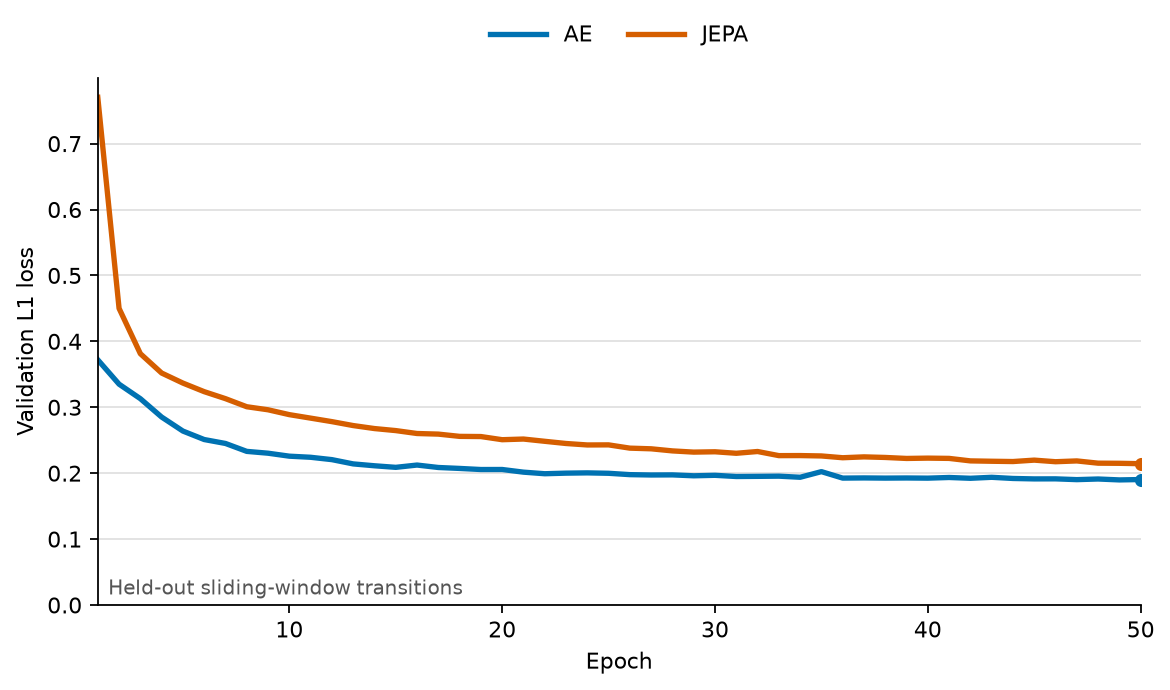

AE   best validation L1: 0.1898 (epoch 49)
JEPA best validation L1: 0.2144 (epoch 50)


In [5]:
import matplotlib.pyplot as plt
import torch

# Validation curves for independently trained AE and JEPA transition models.
curves = {
    'AE': (eval_ae, '#0072B2'),
    'JEPA': (eval_jepa, '#D55E00'),
}

fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=160, layout='constrained')
for name, (losses, color) in curves.items():
    epochs = torch.arange(1, len(losses) + 1)
    ax.plot(epochs, losses, color=color, linewidth=2.4, label=name)
    ax.scatter(epochs[-1], losses[-1], color=color, s=24, zorder=3)

ax.set(xlabel='Epoch', ylabel='Validation L1 loss', xlim=(1, max(len(losses) for losses, _ in curves.values())), ylim=(0, None))
ax.grid(axis='y', color='#D9D9D9', linewidth=0.8, alpha=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.14), columnspacing=1.6, handlelength=2.5)
ax.text(0.01, 0.02, 'Held-out sliding-window transitions', transform=ax.transAxes, fontsize=9, color='#555555')
plt.show()

for name, (losses, _) in curves.items():
    print(f'{name:4s} best validation L1: {min(losses):.4f} (epoch {losses.index(min(losses)) + 1})')

# For a paper figure, optionally save the vector version:
# fig.savefig('window_transition_validation.pdf', bbox_inches='tight')
